# Review 2 — Agglomerative Hierarchical Clustering

This notebook creates customer RFM features, plots a dendrogram, compares Ward/complete/average linkage, reports the three required metrics, and creates PCA plots.

## 1. Load, audit, clean and create RFM features

In [1]:
from pathlib import Path
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans,AgglomerativeClustering
from sklearn.metrics import silhouette_score,davies_bouldin_score,calinski_harabasz_score
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from scipy.cluster.hierarchy import linkage,dendrogram
import joblib
ROOT = Path.cwd().resolve()
while not (ROOT / 'data' / 'Online Retail.xlsx').is_file():
    if ROOT.parent == ROOT:
        raise FileNotFoundError('Dataset not found: data/Online Retail.xlsx')
    ROOT = ROOT.parent
DATA=ROOT/'data'/'Online Retail.xlsx';RESULTS=ROOT/'results'/'clustering';FIGURES=ROOT/'figures'/'clustering';MODELS=ROOT/'models'/'clustering'
for p in [RESULTS,FIGURES,MODELS]:p.mkdir(parents=True,exist_ok=True)
raw=pd.read_excel(DATA);print('Raw shape:',raw.shape);display(raw.isna().sum().sort_values(ascending=False).to_frame('missing_count'))
df=raw.copy();df['InvoiceDate']=pd.to_datetime(df['InvoiceDate'],errors='coerce')
for c in ['CustomerID','Quantity','UnitPrice']:df[c]=pd.to_numeric(df[c],errors='coerce')
df=df.dropna(subset=['CustomerID','InvoiceDate','Quantity','UnitPrice']);df=df[~df['InvoiceNo'].astype(str).str.startswith('C')];df=df[(df['Quantity']>0)&(df['UnitPrice']>0)].drop_duplicates();df['Revenue']=df['Quantity']*df['UnitPrice']
snapshot=df['InvoiceDate'].max()+pd.Timedelta(days=1)
rfm=df.groupby('CustomerID').agg(last_purchase=('InvoiceDate','max'),frequency=('InvoiceNo','nunique'),monetary=('Revenue','sum'),quantity=('Quantity','sum'))
rfm['recency']=(snapshot-rfm['last_purchase']).dt.days;rfm=rfm.drop(columns='last_purchase')[['recency','frequency','monetary','quantity']]
for c in ['frequency','monetary','quantity']:rfm[c]=np.log1p(rfm[c].clip(lower=0))
rfm=rfm.replace([np.inf,-np.inf],np.nan).dropna();rfm.to_csv(RESULTS/'online_retail_customer_rfm.csv',index=True,index_label='CustomerID');print('Customer-level RFM shape:',rfm.shape);display(rfm.head())
scaler=StandardScaler();X_scaled=scaler.fit_transform(rfm)

Raw shape: (541909, 8)


,missing_count
CustomerID,135080
Description,1454
StockCode,0
InvoiceNo,0
Quantity,0
InvoiceDate,0
UnitPrice,0
Country,0


Customer-level RFM shape: (4338, 4)


,recency,frequency,monetary,quantity
CustomerID,,,,
12346.0,326,0.693147,11.253955,11.214735
12347.0,2,2.079442,8.368925,7.807510
12348.0,75,1.609438,7.494564,7.758761
12349.0,19,0.693147,7.472245,6.448889
12350.0,310,0.693147,5.815324,5.288267


## 2. Dendrogram (sampled for readability)

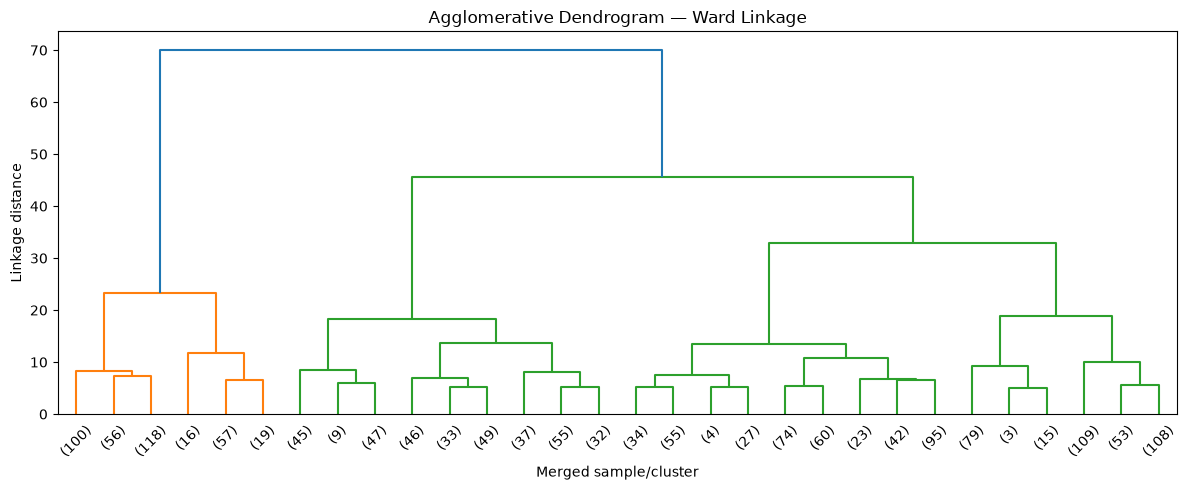

In [2]:
n=min(1500,len(X_scaled));idx=np.sort(np.random.default_rng(42).choice(len(X_scaled),size=n,replace=False));Z=linkage(X_scaled[idx],method='ward');fig,ax=plt.subplots(figsize=(12,5));dendrogram(Z,truncate_mode='lastp',p=30,show_leaf_counts=True,ax=ax);ax.set_title('Agglomerative Dendrogram — Ward Linkage');ax.set_xlabel('Merged sample/cluster');ax.set_ylabel('Linkage distance');fig.tight_layout();fig.savefig(FIGURES/'agglomerative_dendrogram.png',dpi=150);plt.show()

## 3. Compare linkage methods and clustering metrics

In [3]:
K=4;rows=[];labels_by_method={}
for method in ['ward','complete','average']:
 model=AgglomerativeClustering(n_clusters=K,linkage=method);lab=model.fit_predict(X_scaled);labels_by_method[method]=lab
 rows.append({'algorithm':f'Agglomerative ({method})','linkage':method,'n_clusters':len(np.unique(lab)),'silhouette':silhouette_score(X_scaled,lab),'davies_bouldin':davies_bouldin_score(X_scaled,lab),'calinski_harabasz':calinski_harabasz_score(X_scaled,lab)})
comparison=pd.DataFrame(rows);display(comparison.round(4));comparison.to_csv(RESULTS/'agglomerative_linkage_comparison.csv',index=False)

,algorithm,linkage,n_clusters,silhouette,davies_bouldin,calinski_harabasz
0,Agglomerative (ward),ward,4,0.3106,0.9885,3408.3823
1,Agglomerative (complete),complete,4,0.2701,0.8973,1721.1058
2,Agglomerative (average),average,4,0.3303,0.6893,77.2785


## 4. PCA plot for each linkage strategy

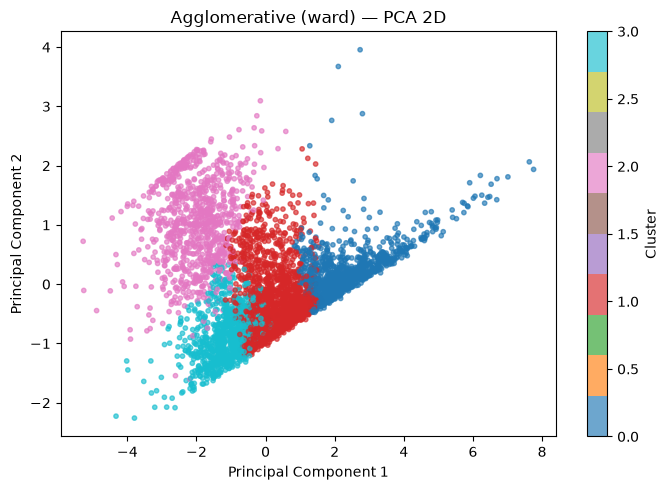

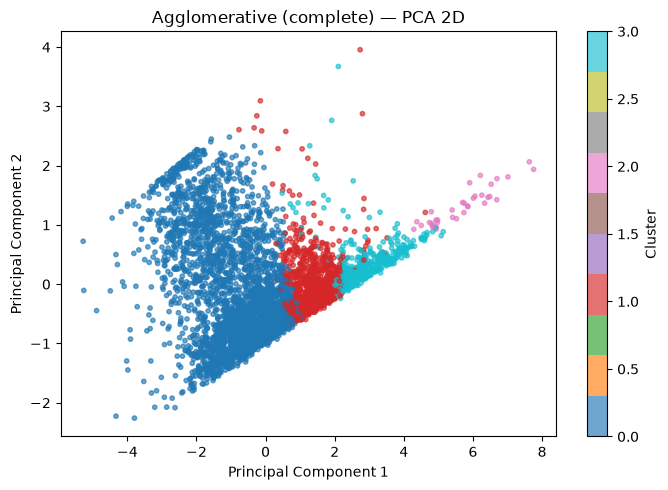

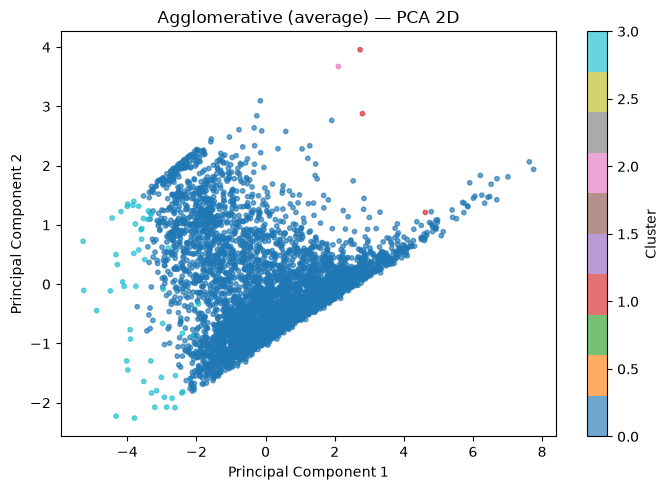

In [4]:
Xp=PCA(n_components=2,random_state=42).fit_transform(X_scaled)
for method,lab in labels_by_method.items():
 fig,ax=plt.subplots(figsize=(7,5));sc=ax.scatter(Xp[:,0],Xp[:,1],c=lab,s=10,alpha=.65,cmap='tab10');ax.set_title(f'Agglomerative ({method}) — PCA 2D');ax.set_xlabel('Principal Component 1');ax.set_ylabel('Principal Component 2');fig.colorbar(sc,ax=ax,label='Cluster');fig.tight_layout();fig.savefig(FIGURES/f'agglomerative_{method}_pca.png',dpi=150);plt.show()

## 5. Save customer cluster labels

In [5]:
out=rfm.copy()
for method,lab in labels_by_method.items():out[f'agglomerative_{method}_cluster']=lab
out.to_csv(RESULTS/'agglomerative_customer_labels.csv',index=True,index_label='CustomerID');print('Saved labels for all linkage strategies.')

Saved labels for all linkage strategies.
